In [1]:
import json
import os

from IPython.display import Image, Markdown, display


def load(name):
    with open(os.path.join("parts", name + ".json")) as file:
        return json.load(file)


def cell(value, form):
    if value is None:
        return "—"
    if callable(form):
        return form(value)
    return format(value, form) if form else str(value)


def table(rows, columns):
    """columns: (header, a key or a function of the row, a format spec or a function)"""
    def value(row, pick):
        return pick(row) if callable(pick) else row.get(pick)
    lines = ["| " + " | ".join(header for header, _, _ in columns) + " |",
             "|" + "---|" * len(columns)]
    for row in rows:
        lines.append("| " + " | ".join(cell(value(row, pick), form) for _, pick, form in columns) + " |")
    display(Markdown("\n".join(lines)))


def figure(path):
    display(Image(filename=path, width=720))

# EP4 measurement: NVIDIA GeForce RTX 5070 Laptop GPU

2026-11-22 17:06:33 · host `Welton` · engine code `72b86b63cbf7` ·
`python main.py measure --parts validation,devices,kernel --seconds 0.3 --repeats 1 --allow-invalid --yes`

**What this is.** The raw results of one `measure` run: every engine run it made is a file in `points/`, every
analysis a file in `parts/`, every figure in `figures/`. The tables below are read from those files when the notebook
runs, so re-running it rebuilds them; the sentences that interpret them were written from the same numbers.

## The machine

| | |
|---|---|
| GPU | NVIDIA GeForce RTX 5070 Laptop GPU, compute capability 12.0, 36 SMs |
| per SM | 65536 registers, 1536 threads, 24 blocks |
| CPU (the reference) | Intel(R) Core(TM) Ultra 7 255HX, one core |
| software | Build cuda_13.3.r13.3/compiler.38244171_0; driver 621.14 |

## What makes a valid run

A run measures speed only if the GPU is busy long enough and evenly enough. Two rules, the larger wins: (1) at least 1 s of photons, so that the launch and the clock's ramp-up don't dominate; (2) at least 32 chunks per resident thread, so that every SM gets a fair share and the slowest one doesn't decide the time (at 10⁷ photons on the laptop: 9 766 chunks for ~28 800 threads, and pass times varied 0.6–1.6×; research/pass_order.py).

| binary | minimum N | by time (1 s) | by work (32 chunks per thread) | resident threads | N used here |
|---|---|---|---|---|---|
| cpu64 | 8.00e+06 | 8.00e+06 | 3.28e+04 | 1 | 8.00e+06 |
| cpu32 | 1.20e+07 | 1.20e+07 | 3.28e+04 | 1 | 1.50e+07 |
| gpu64 | 9.06e+08 | 6.43e+08 | 9.06e+08 | 27648 | 1.00e+09 |
| gpu32 | 1.10e+10 | 1.10e+10 | 1.06e+09 | 32256 | 1.50e+10 |

The CPU is one core, so one resident thread: its minimum is set by time alone. Two parts are below the GPU's minimum
**by design**: p(N) and the small-N strong sweep, whose point is to show what happens when the work is too small.
The validation checks use N = 10⁸, set by the statistics they need, not by speed.

## 1. Is the physics right? (validation)

**Question.** Does the GPU compute the same star as the CPU engine, and the same physics as EP2?

**Method.**
- *EP2 vs EP4:* both programs, no spots, **independent** random numbers; the χ² of the difference between the two
  images (frames summed), per degree of freedom. Equal physics gives χ²/dof ≈ 1 (|σ| < 3 passes).
- *FP32 vs FP64:* the same seed, so the same photons; the fraction of photons that land in another pixel in FP32,
  next to the Poisson noise per lit pixel.
- *GPU vs CPU:* the same seed, the same photons; the images compared bit for bit.

In [2]:
checks = load("validation")["checks"]
table(checks, [("check", lambda c: f"{c['name']} ({c['processor']}{c['precision']})", None),
               ("N", lambda c: c["data"].get("photons"), ".1e"),
               ("passed", "passed", lambda v: {True: "yes", False: "NO"}.get(v, "—")),
               ("result", "headline", None)])

| check | N | passed | result |
|---|---|---|---|
| ep2 (gpu64) | 1.0e+08 | yes | χ²/dof = 0.9987: the same physics within noise |
| precision (gpu64) | 1.0e+09 | — | FP32 moves 1.06e-04 of the photons (noise 3.88e-02); 17.61× the speed of FP64 |
| gpu (gpu64) | 1.0e+08 | yes | the images are identical, bit for bit; 69× one CPU core on the photons, 26× on the whole run |
| gpu (gpu32) | 1.0e+08 | — | 699 pixels differ (4.14e-05 of the photons moved); 678× one CPU core on the photons, 31× on the whole run |

**What it means.**
- EP2 vs EP4: χ²/dof = 0.9987 over 126227 pixels, -0.32 σ from 1:
  the same physics within the noise.
- FP32 moves 1.06e-04 of the photons to another pixel; the noise per lit pixel is
  3.88e-02, so the FP32 error is 368× smaller than the noise. FP32 is
  17.6× faster than FP64 on this GPU.
- GPU vs CPU, FP64: identical, bit for bit.
  FP32: 4.14e-05 of the photons moved (the GPU's `sinf`,
  `cosf` and fused multiply-adds round differently from the CPU's).

**Caveats.** The χ² test is statistical: about 1 run in 370 fails it by chance. The bit-for-bit results hold for this
build and this seed; they don't depend on N.

## 2. How fast is each engine? (devices)

**Question.** Photons per second of the GPU (all SMs) and of one CPU core, in FP64 and FP32.

**Method.** The default star (200² pixels, 150 frames, 4 observers, one pass), N = the reference N of each binary,
repeated. The speed is N over the photon phase alone (the kernel, or the CPU's loop): setup and save are left out.

| binary | machine | units | N | photons/s (median) | min – max | repeats |
|---|---|---|---|---|---|---|
| cpu64 | Intel(R) Core(TM) Ultra 7 255HX | 1 | 8.0e+06 | 9.29e+06 | 9.29e+06 – 9.29e+06 | 1 |
| cpu32 | Intel(R) Core(TM) Ultra 7 255HX | 1 | 1.5e+07 | 1.4e+07 | 1.4e+07 – 1.4e+07 | 1 |
| gpu64 | NVIDIA GeForce RTX 5070 Laptop GPU | 36 | 1.0e+09 | 6.44e+08 | 6.44e+08 – 6.44e+08 | 1 |
| gpu32 | NVIDIA GeForce RTX 5070 Laptop GPU | 36 | 1.5e+10 | 1.08e+10 | 1.08e+10 – 1.08e+10 | 1 |

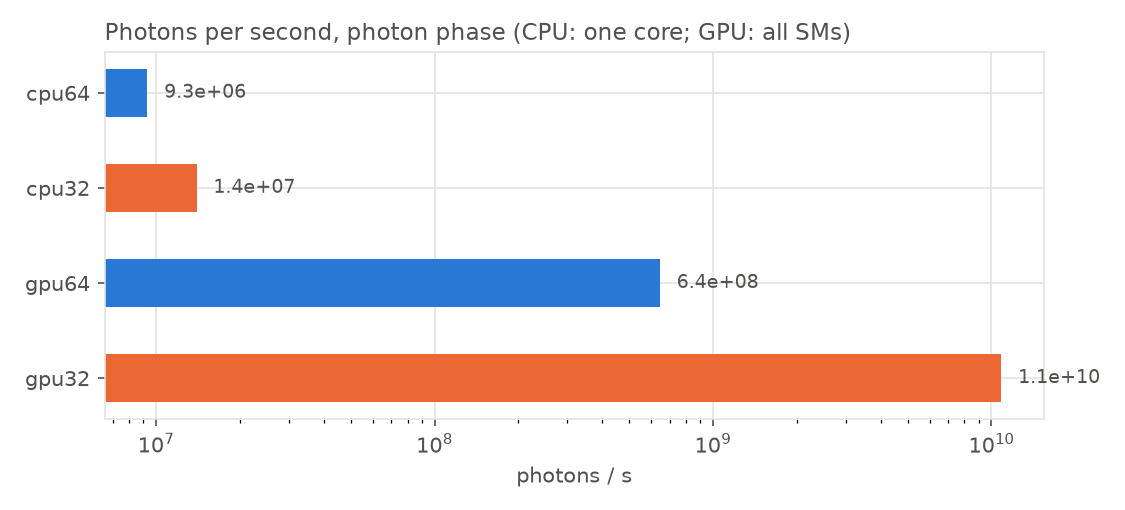

In [3]:
devices = load("devices")
table(devices["rows"], [("binary", "binary", None), ("machine", "machine", None), ("units", "units", None),
                        ("N", "photons", ".1e"),
                        ("photons/s (median)", lambda r: r["photons_per_second"]["median"], ".3g"),
                        ("min – max", lambda r: f"{r['photons_per_second']['min']:.3g} – {r['photons_per_second']['max']:.3g}", None),
                        ("repeats", lambda r: r["photons_per_second"]["repeats"], None)])
figure("figures/devices.png")

**What it means.**
- The GPU against one CPU core: 69× in FP64, 777× in FP32.
- FP32 over FP64: 16.8× on the GPU, 1.50× on the CPU.
  The CPU does FP64 almost as fast as FP32; this GPU has few FP64 units, so FP64 photons cost far more there.
- GPU FP64: 6.44e+08 photons/s; GPU FP32:
  1.08e+10 photons/s.

**Caveats.** The CPU is a reference, not a competitor: one core of a laptop CPU, whose speed varies by ~20% between
cores and sessions (`research/cpu_baseline.py`). The speedups are ratios of medians measured in the same run.

## 3. What the kernel is made of (kernel)

**Question.** What does the compiler make of `trace_photons`, and which changes to it matter?

**Method.** The resources come from the compiler (`ptxas -v`) and the CUDA runtime (`cudaFuncGetAttributes`, the
occupancy API). The instruction mix counts the instructions in the kernel's machine code (SASS) by the unit that runs
them. Each variant is a rebuild with one change, run at the same N as the baseline:
- `scene_in_global`: the scene in global memory instead of constant memory;
- `no_fma`: no fused multiply-adds (`--fmad=false`);
- `sections`: timers around each piece of the photon (cycles per section), to see where the time goes.

In [4]:
kernel = load("kernel")
print("Resources")
table([dict(r, precision=p) for p, r in kernel["resources"].items()],
      [("precision", "precision", None), ("registers", "registers", None), ("spills (B)", "spill_bytes", None),
       ("constant (B)", "constant_bytes", None), ("threads/block", "threads_per_block", None),
       ("blocks/SM", "blocks_per_sm", None), ("occupancy", "occupancy", ".2f")])
mix = kernel["instruction_mix"]
units = sorted({unit for counts in mix.values() for unit in counts})
print("Instruction mix (static: instructions in the code, not how often they run)")
table([dict({"unit": unit}, **{name: counts.get(unit, 0) for name, counts in mix.items()}) for unit in units],
      [("unit", "unit", None)] + [(name, name, None) for name in mix])
for precision, rows in kernel["variants"].items():
    print(f"Variants, {precision}")
    table(rows, [("variant", "variant", None), ("registers", "registers", None), ("spills (B)", "spill_bytes", None),
                 ("kernel (s)", lambda r: r["kernel_time"]["median"], ".3f"),
                 ("time vs baseline", "time_vs_baseline", ".3f"), ("cycles vs baseline", "cycles_vs_baseline", ".3f"),
                 ("same image", "image_equals_baseline", lambda v: "yes" if v else "no")])
for precision, sections in kernel["sections"].items():
    print(f"Where the time goes, {precision} (cycles per section, the sections build)")
    table(sorted(sections, key=lambda s: -s["share"]), [("section", "name", None), ("share", "share", ".1%")])

Resources


| precision | registers | spills (B) | constant (B) | threads/block | blocks/SM | occupancy |
|---|---|---|---|---|---|---|
| fp64 | 80 | 0 | 18048 | 768 | 1 | 0.50 |
| fp32 | 67 | 0 | 17256 | 896 | 1 | 0.58 |

Instruction mix (static: instructions in the code, not how often they run)


| unit | star_gpu64 | star_gpu32 |
|---|---|---|
| FP32 cores | 73 | 247 |
| FP64 units | 278 | 4 |
| atomics (L2) | 2 | 2 |
| constant loads | 46 | 49 |
| control flow | 1261 | 296 |
| conversions | 25 | 25 |
| global memory | 14 | 5 |
| integer units | 660 | 624 |
| local memory (stack, spills) | 5 | 20 |
| moves, special registers | 250 | 154 |
| other | 45 | 48 |
| special function unit (MUFU) | 13 | 12 |
| uniform datapath | 66 | 28 |
| warp-wide | 6 | 6 |

Variants, fp64


| variant | registers | spills (B) | kernel (s) | time vs baseline | cycles vs baseline | same image |
|---|---|---|---|---|---|---|
| baseline | 80 | 0 | 1.552 | 1.000 | 1.000 | yes |
| scene_in_global | 88 | 0 | 1.541 | 0.993 | 0.994 | yes |
| no_fma | 80 | 0 | 1.666 | 1.073 | 1.072 | yes |
| sections | 112 | 0 | 1.535 | 0.989 | 0.988 | yes |

... (2 outputs left out)

Where the time goes, fp64 (cycles per section, the sections build)


| section | share |
|---|---|
| direction | 33.4% |
| bin | 21.6% |
| surface | 20.2% |
| record | 15.0% |
| spots | 8.4% |
| pixel | 1.4% |
| chunk | 0.0% |

Where the time goes, fp32 (cycles per section, the sections build)


| section | share |
|---|---|
| direction | 40.8% |
| surface | 27.6% |
| record | 13.2% |
| spots | 9.2% |
| bin | 8.4% |
| pixel | 0.9% |
| chunk | 0.0% |

**What it means.**
- Registers: 80 (FP64) and 67 (FP32),
  spills 0 / 0 bytes; the launch
  gives occupancy 0.50 / 0.58
  (section 4 explains why).
- Constant vs global memory for the scene: no difference (0.99× the time in FP64, 1.02× in FP32). Every thread of a warp reads the same scene value at the same time, which the constant cache broadcasts, and L1 serves just as well.
- No FMA (separate multiply and add): 1.07× the time in FP64, 1.02× in FP32; the FP64 image is the same: fusing changed no photon's pixel here.
- The section timers cost 0.99× (FP64) and 1.08× (FP32): measuring changes what is measured. The largest section is *direction* (33% of the cycles, FP64) and *direction* (41%, FP32).

**Caveats.** The mix is static: a `NOP` or an FP64 instruction in a branch that never runs is counted like any other
(`research/nop_runs.py`, `research/fp64_in_fp32_kernel.py`). Times are medians of the repeats; their spread is in
`parts/kernel.json`.

## Appendix: the data

**The folder.**
- `run.json`: what was asked (the options, the reference N per binary), the machine, the status.
- `machine.json`: the GPU's limits, the software, the environment checks, the minimum N.
- `plan.json`: every planned run with its prediction (seconds, memory, passes) and its validity.
- `points/<run>.json`: one file per engine run (the name says the binary, the variant, the SMs, N and the repeat).
- `parts/<part>.json`: the analyses, which these tables read:
- `parts/validation.json`
- `parts/devices.json`
- `parts/kernel.json`
- `figures/`: the figures, each with a `.json` of the numbers it plots.
- `progress.log`: each run's measured vs predicted time.

**The fields of a point.**

| field | meaning |
|---|---|
| `processor, precision, sms, photons, variant, repeat, star` | what was asked (sms empty = all SMs) |
| `SUMMARY.PHOTONS_TIME` | seconds of the photon phase (the kernel, or the CPU loop): the speed is measured on it |
| `SUMMARY.TIME` | seconds of the whole engine run: setup + zero + photons + copy + save |
| `SUMMARY.SETUP_TIME, ZERO_TIME, COPY_TIME, SAVE_TIME` | the serial parts of the run |
| `SUMMARY.PHOTONS_PER_SECOND` | N / PHOTONS_TIME |
| `SUMMARY.RECORDED, BLOCKED, MISSED` | photons that reached an observer's image, hit a spot, or no observer's μ bin |
| `SUMMARY.REGISTERS_PER_THREAD, LOCAL_BYTES_PER_THREAD` | the kernel's registers, and its local memory (spills) |
| `SUMMARY.THREADS_PER_BLOCK, BLOCKS_PER_UNIT, OCCUPANCY` | the launch chosen by the occupancy API |
| `KERNEL[].KERNEL_TIME` | seconds of each pass's kernel, from CUDA events |
| `SMS[].CYCLES` | clock cycles of the slowest SM in each pass: speed with the clock removed |
| `GPU_MONITOR.*` | nvidia-smi sampled every 200 ms: clock (MHz), power (W), temperature, and the share of samples with each clock-limit reason active (POWER_CAP, VOLTAGE_CEILING, ...) |
| `IMAGE_DIGEST` | a hash of the observers' images: equal digests = identical images, bit for bit |
| `PROCESS_TIME` | wall-clock seconds of the engine process, measured from Python |
| `validity` | valid, below the minimum by design (p(N), small N), or INVALID |